# Nonlinear regression: logistic growth of one chick

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sym
from scipy.optimize import least_squares
from scipy.stats import t
from ipywidgets import interact, FloatSlider

The data `ChickWeight` (Crowder & Hand, 1990, Analysis of Repeated Measures) have the weight (in grams) of 50 chicks, measured every two days from birth until day 20, and on day 21. Each chick received one of four diets.

This is the first of three notebooks. Here we fit a logistic growth curve to one chick, by hand. In the second we fit all the chicks of one diet, where the variance is not constant, and in the third all the diets at once.

In [2]:
dat = pd.read_csv('chick_weight.csv')
dat = dat.rename(columns={'Weight': 'weight'})
dat['Diet'] = dat['Diet'].astype('category')
dat.head()

,weight,Time,Chick,Diet
0,42,0,1,1
1,51,2,1,1
2,59,4,1,1
3,64,6,1,1
4,76,8,1,1


In [3]:
# Colors: one for each diet, the same in the three notebooks
diet_colors = {1: '#0072B2', 2: '#E69F00', 3: '#009E73', 4: '#CC79A7'}

point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'

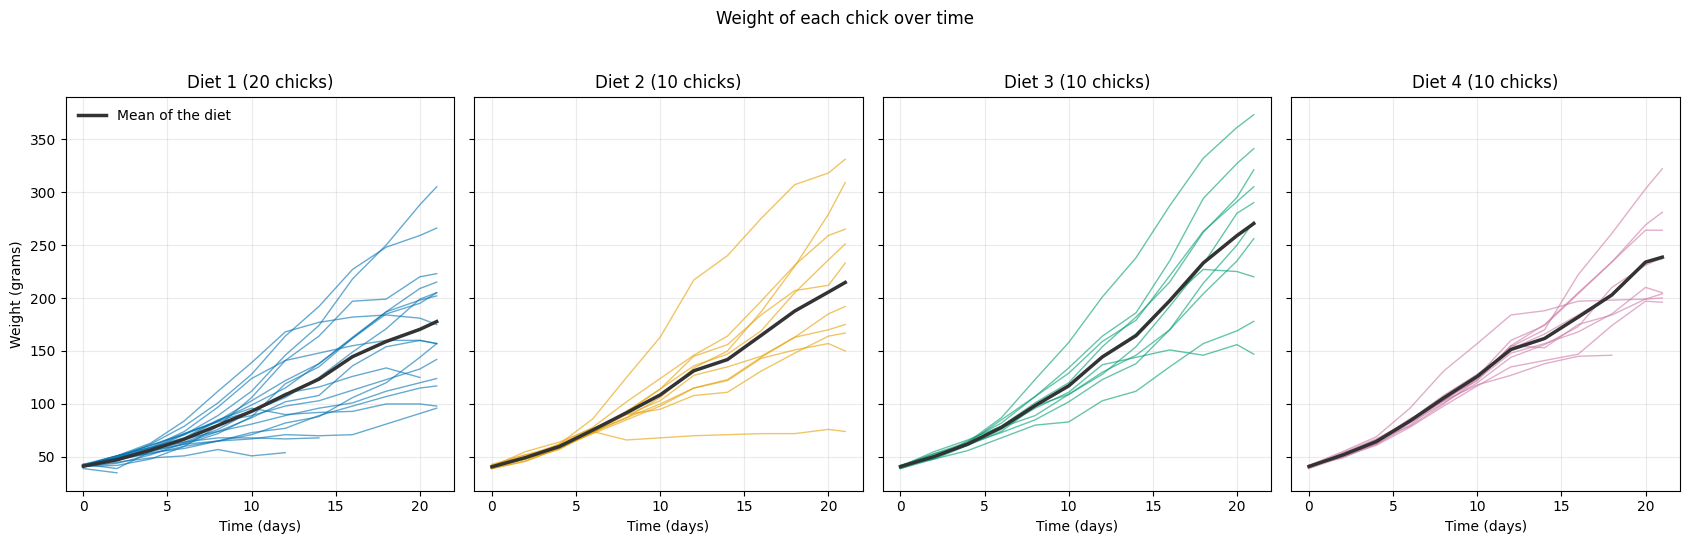

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 5.5), sharey=True)
for ax, diet in zip(axes, [1, 2, 3, 4]):
    dat_diet = dat[dat['Diet'] == diet]
    for chick, dat_chick in dat_diet.groupby('Chick'):
        ax.plot(dat_chick['Time'], dat_chick['weight'], color=diet_colors[diet], lw=1, alpha=0.6)
    mean = dat_diet.groupby('Time')['weight'].mean()
    ax.plot(mean.index, mean, color='#333333', lw=2.5, label='Mean of the diet')
    ax.set_xlabel('Time (days)')
    ax.set_title(f'Diet {diet} ({dat_diet["Chick"].nunique()} chicks)')
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Weight (grams)')
axes[0].legend(loc='upper left', frameon=False)
fig.suptitle('Weight of each chick over time')
fig.tight_layout(rect=(0, 0, 1, 0.95))

## One chick

Let's select just the chick number 3

In [5]:
dat_example = dat.loc[dat['Chick'] == 3, ['weight', 'Time']].reset_index(drop=True)

Y = dat_example['weight'].to_numpy(dtype=float)
x = dat_example['Time'].to_numpy(dtype=float)
n = len(Y)
p = 3

x_grid = np.linspace(0, 21, 200)

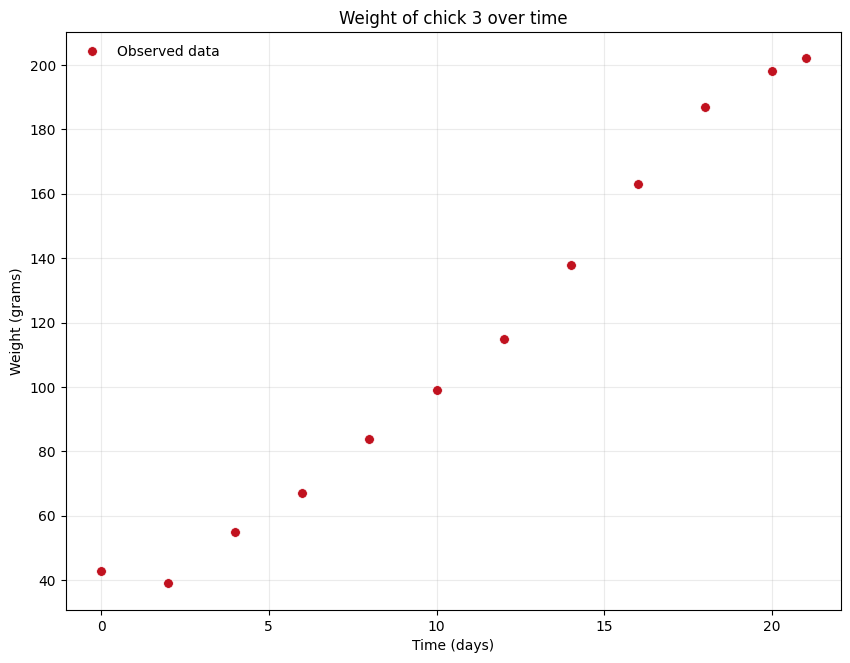

In [6]:
def plot_chick(ax):
    ax.plot(x, Y, 'o', color=point_color, markersize=7, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data')
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('Weight (grams)')
    ax.grid(True, alpha=0.25)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_chick(ax)
ax.set_title('Weight of chick 3 over time')
ax.legend(loc='upper left', frameon=False)

## The logistic growth model

We are going to model the weight with a logistic growth curve,
$$f(t; M, r, b) = \frac{M}{1+e^{-r(t-b)}},$$
where $M$ is the maximum weight, $b$ the time at which the chick reaches half of it (and grows the fastest), and $r$ the growth rate. The model is not linear in $r$ and $b$, so there is no closed formula for the least squares estimators.

Move the sliders to see what each parameter does, and to look for reasonable initial values (this cell needs a running kernel).

In [7]:
def f(t, M, r, b):
    return(M/(1+np.exp(-r*(t-b))))

def interactive_growth(M, r, b):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.plot(x_grid, f(x_grid, M, r, b), color=line_color, lw=2, label='Logistic growth curve')
    plot_chick(ax)
    ax.set_ylim(0, 320)
    ax.set_title(f'M = {M:g}, r = {r:g}, b = {b:g}, SSE = {sum((Y - f(x, M, r, b))**2):.0f}')
    ax.legend(loc='upper left', frameon=False)
    plt.show()

interact(interactive_growth,
         M=FloatSlider(value=202, min=100, max=600, step=5, description='M'),
         r=FloatSlider(value=0.1, min=0.02, max=0.5, step=0.01, description='r'),
         b=FloatSlider(value=15, min=0, max=30, step=0.5, description='b'));

interactive(children=(FloatSlider(value=202.0, description='M', max=600.0, min=100.0, step=5.0), FloatSlider(v…

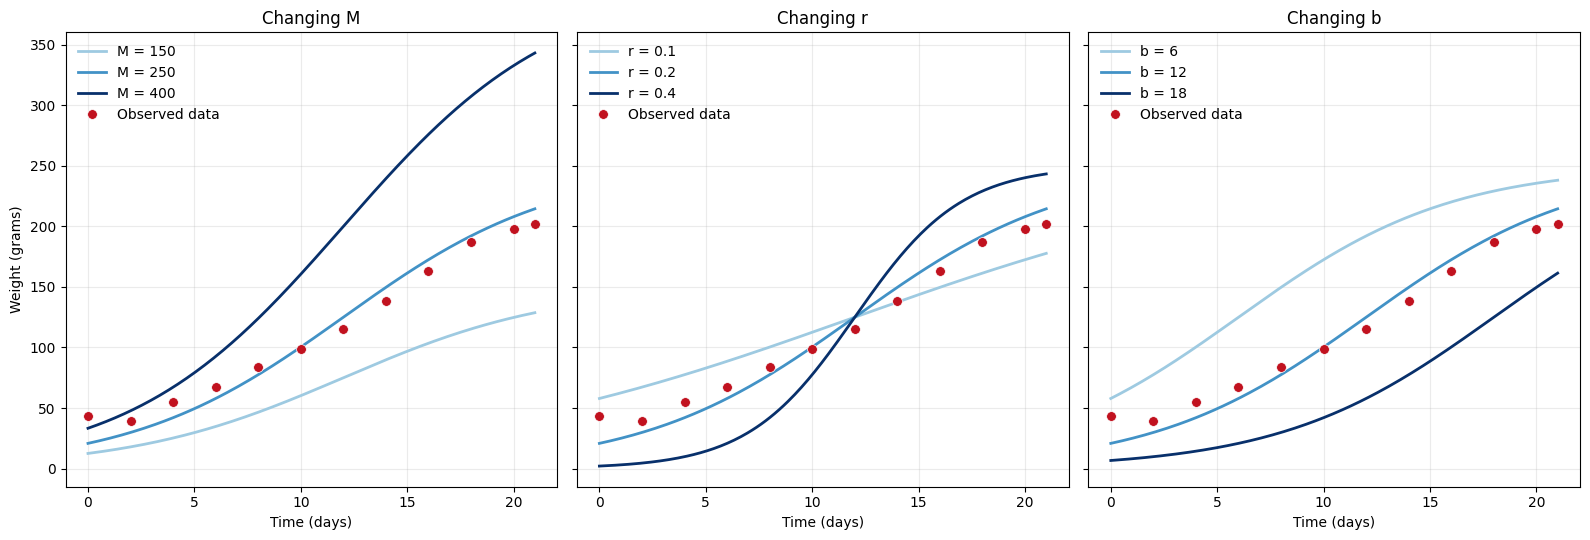

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
families = [('M', [150, 250, 400], lambda v: (v, 0.2, 12)),
            ('r', [0.1, 0.2, 0.4], lambda v: (250, v, 12)),
            ('b', [6, 12, 18], lambda v: (250, 0.2, v))]
for ax, (name, values, params) in zip(axes, families):
    for value, shade in zip(values, ['#9ecae1', '#4292c6', '#08306b']):
        ax.plot(x_grid, f(x_grid, *params(value)), color=shade, lw=2, label=f'{name} = {value}')
    plot_chick(ax)
    ax.set_title(f'Changing {name}')
    ax.legend(loc='upper left', frameon=False)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout()

## Gauss-Newton by hand

We linearize the model around the current value $\theta^{(k)}$ of the parameters. With $F$ the matrix of the derivatives of $f$ with respect to the parameters (one row for each observation), each iteration solves a linear least squares problem,
$$\theta^{(k+1)} = \theta^{(k)} + (F^TF)^{-1}F^T(y - f(\theta^{(k)})).$$

The derivatives, with `sympy`:

In [9]:
M_s, r_s, b_s, t_s = sym.symbols('M r b t')
f_s = M_s/(1+sym.exp(-r_s*(t_s-b_s)))

sym.diff(f_s, M_s)

1/(1 + exp(-r*(-b + t)))

In [10]:
sym.diff(f_s, r_s)

-M*(b - t)*exp(-r*(-b + t))/(1 + exp(-r*(-b + t)))**2

In [11]:
sym.diff(f_s, b_s)

-M*r*exp(-r*(-b + t))/(1 + exp(-r*(-b + t)))**2

In [12]:
def F_1(t,M,r,b):
    return(1/(1+np.exp(-r*(t-b))))

def F_2(t,M,r,b):
    return((M*(t-b)*np.exp(-r*(t-b)))/(1+np.exp(-r*(t-b)))**2)

def F_3(t,M,r,b):
    return((-M*r*np.exp(-r*(t-b)))/(1+np.exp(-r*(t-b)))**2)

def gradient(t, theta):
    # Matrix F: one row for each time, one column for each parameter
    return np.vstack([F_1(t, *theta), F_2(t, *theta), F_3(t, *theta)]).T

In [13]:
# Initialize
M0 = Y.max()
r0 = 0.1
b0 = 15

theta = np.array([M0, r0, b0])

tolm   = 1e-6       # tolerance (minimum norm of the difference of the betas)
iterm  = 100        # maximum number of iterations
tolera = 1          # initialize tolera
itera  = 0          # initialize ittera
histo  = theta      # initialize beta upgrade

while((tolera > tolm) and (itera < iterm)):
    F_matrix = gradient(x, theta)
    Y_hat = f(x, *theta)
    delta = np.linalg.solve(F_matrix.T @ F_matrix, F_matrix.T @ (Y-Y_hat))
    theta = theta + delta
    tolera = np.sqrt(sum(delta**2))
    histo  = np.vstack([histo, theta])
    itera  = itera+1

pd.DataFrame(histo, columns=['M', 'r', 'b']).rename_axis('iteration')

,M,r,b
iteration,,,
0,202.000000,0.100000,15.000000
1,329.091107,0.135659,18.144028
2,279.011356,0.135356,14.410758
3,298.526078,0.135611,15.022783
4,296.917386,0.136411,14.892768
5,297.107471,0.136357,14.903175
6,297.092674,0.136362,14.902353
7,297.093646,0.136362,14.902407
8,297.093577,0.136362,14.902403


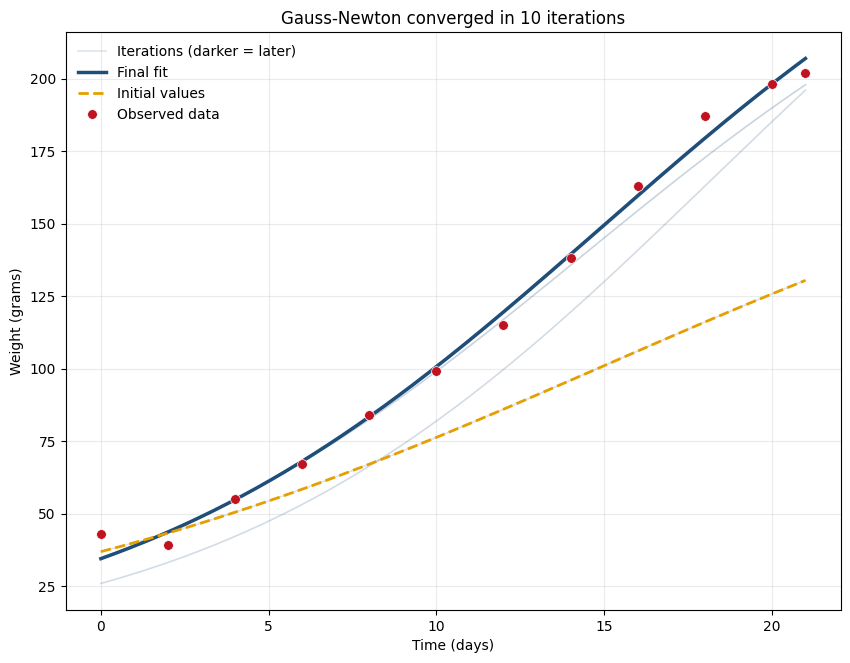

In [14]:
fig, ax = plt.subplots(figsize=(10, 7.5))
n_iter = len(histo)
for k, theta_k in enumerate(histo):
    last = k == n_iter-1
    ax.plot(x_grid, f(x_grid, *theta_k), color=line_color, lw=2.5 if last else 1.2,
            alpha=1 if last else 0.15 + 0.5*k/n_iter,
            label='Final fit' if last else ('Iterations (darker = later)' if k == 0 else None))
ax.plot(x_grid, f(x_grid, *histo[0]), '--', color='#E69F00', lw=2, label='Initial values')
plot_chick(ax)
ax.set_title(f'Gauss-Newton converged in {itera} iterations')
ax.legend(loc='upper left', frameon=False)

## Using scipy least squares

In [15]:
def logistic_gowth(theta, t):
    return theta[0] / (1 + np.exp(- theta[1] * (t - theta[2])))

def fun(theta):
    return logistic_gowth(theta, x) - Y

theta0 = [M0,r0,b0]
log_growth = least_squares(fun, theta0)

print('By hand:', theta)
print('scipy:  ', log_growth.x)

By hand: [2.97093581e+02 1.36361614e-01 1.49024036e+01]
scipy:   [2.97093647e+02 1.36361591e-01 1.49024072e+01]


The jacobian that `scipy` returns is our matrix $F$ at the solution.

In [16]:
F_matrix = gradient(x, theta)
print('Largest difference between F and the jacobian of scipy:', np.max(np.abs(F_matrix - log_growth.jac)))

Largest difference between F and the jacobian of scipy: 0.00028660349869369384


## Inference

Asymptotically, $\hat\theta \approx N\left(\theta, \sigma^2(F^TF)^{-1}\right)$, with $\hat\sigma^2 = SSE/(n-p)$.

In [17]:
Y_hat = f(x, *theta)
hat_sigma2 = sum((Y-Y_hat)**2)/(n-p)
var_matrix_params = hat_sigma2 * np.linalg.inv(F_matrix.T @ F_matrix)

# Significance of the estimators
alpha = 0.05
se_params = np.sqrt(np.diag(var_matrix_params))
t_score = theta/se_params
p_value = 2*(1-t.cdf(np.abs(t_score), n-p))
q_t = t.ppf(1-alpha/2, n-p)

pd.DataFrame({'estimate': theta, 'std. error': se_params, 't': t_score, 'p-value': p_value,
              'lower': theta - q_t*se_params, 'upper': theta + q_t*se_params}, index=['M', 'r', 'b']).round(4)

,estimate,std. error,t,p-value,lower,upper
M,297.0936,30.1338,9.8591,0.0,228.9261,365.2611
r,0.1364,0.0120,11.3222,0.0,0.1091,0.1636
b,14.9024,1.6553,9.0028,0.0,11.1578,18.6470


### Confidence and prediction intervals

By the delta method, the variance of the fitted curve at a time $t$ is $F_t\,\mathrm{Var}(\hat\theta)\,F_t^T$, where $F_t$ is the row of derivatives at that time. For the prediction of a new observation we add $\hat\sigma^2$.

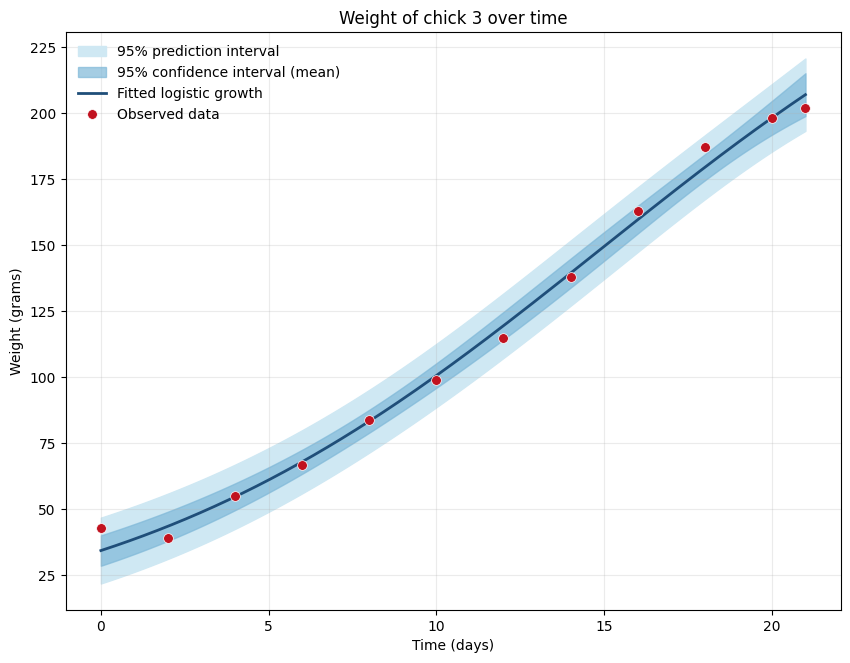

In [18]:
x_long = np.linspace(0, 40, 300)

def intervals(t_values):
    F_t = gradient(t_values, theta)
    fit = f(t_values, *theta)
    var_mean = np.sum((F_t @ var_matrix_params) * F_t, axis=1)
    ci = q_t*np.sqrt(var_mean)
    pi = q_t*np.sqrt(hat_sigma2 + var_mean)
    return fit, fit-ci, fit+ci, fit-pi, fit+pi

def plot_fit(ax, t_values, title):
    fit, ci_lower, ci_upper, pi_lower, pi_upper = intervals(t_values)
    ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
    pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
    ax.fill_between(t_values, pi_lower, pi_upper, color=pi_color, label=pi_label)
    ax.fill_between(t_values, ci_lower, ci_upper, color=ci_color, alpha=0.7, label=ci_label)
    ax.plot(t_values, fit, color=line_color, lw=2, label='Fitted logistic growth')
    plot_chick(ax)
    ax.set_title(title)
    ax.legend(loc='upper left', frameon=False)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_fit(ax, x_grid, 'Weight of chick 3 over time')

### Extrapolating

The chick was observed until day 21, before the curve flattens. The data have little information about the maximum weight $M$, and the intervals show it as soon as we leave the observed range.

Text(-4, 5, '$\\hat M$ = 297')

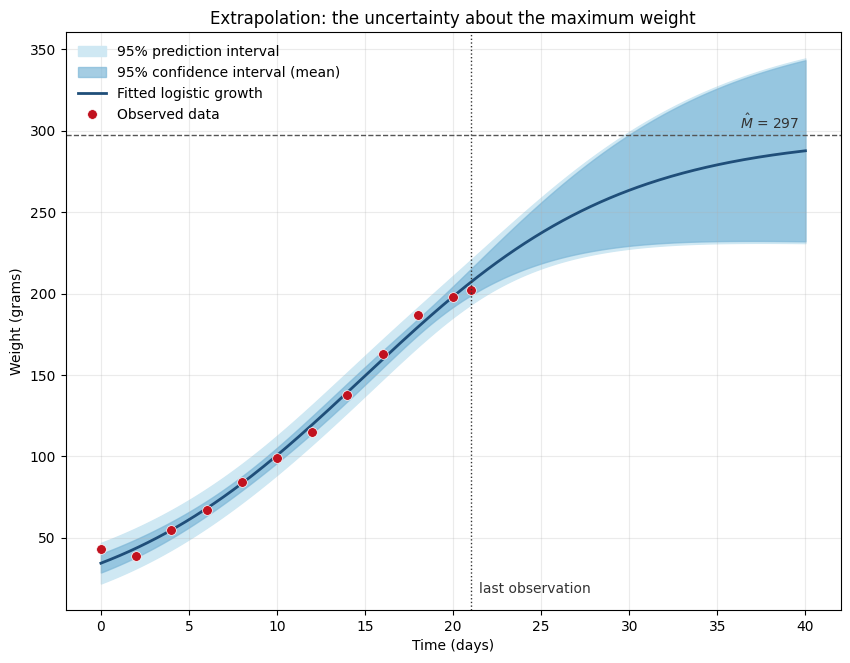

In [19]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_fit(ax, x_long, 'Extrapolation: the uncertainty about the maximum weight')
ax.axvline(21, ls=':', color='#333333', lw=1)
ax.annotate('last observation', (21, 0.03), xycoords=('data', 'axes fraction'), xytext=(6, 0),
            textcoords='offset points', fontsize=10, color='#333333')
ax.axhline(theta[0], ls='--', color='#555555', lw=1)
ax.annotate(f'$\\hat M$ = {theta[0]:.0f}', (40, theta[0]), xytext=(-4, 5), textcoords='offset points', ha='right',
            fontsize=10, color='#333333')